# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Виконала:** Сєднєва Уляна, група 4-10  
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/lab7

**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Завантаження файлу в Google Colab
# from google.colab import files
# files.upload()
# df = pd.read_csv('data.csv')
# df.head()

In [3]:
# Варіант 2. Завантаження датасету через KaggleHub
# (якщо KaggleHub недоступний — автоматично завантажуємо той самий файл data.csv з Google Drive)
import os
import warnings
warnings.filterwarnings('ignore')

try:
    import kagglehub
    path = kagglehub.dataset_download('unmoved/cure-the-princess')
    df = pd.read_csv(os.path.join(path, 'data.csv'))
    print('Дані завантажено через KaggleHub')
except Exception as e:
    print('KaggleHub недоступний:', type(e).__name__, '— завантажуємо з Google Drive')
    import gdown
    gdown.download(id='1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH', output='data.csv', quiet=True)
    df = pd.read_csv('data.csv')
    print('Дані завантажено з Google Drive')
df.head()

100%|██████████| 49.2k/49.2k [00:00<00:00, 4.06MB/s]

Extracting files...
Дані завантажено через KaggleHub


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# Перші рядки, структура й розмір датасету
display(df.head())
df.info()
print('\nРозмір датасету:', df.shape, f'({df.shape[0]} рядків, {df.shape[1]} стовпців)')

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB

Розмір датасету: (2338, 14) (2338 рядків, 14 стовпців)


In [5]:
# Пропуски та дублікати
missing = df.isnull().sum()
print('Пропущені значення за стовпцями:')
print(missing)
print('\nУсього пропусків:', int(missing.sum()))
print('Кількість повних дублікатів рядків:', int(df.duplicated().sum()))

Пропущені значення за стовпцями:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Усього пропусків: 0
Кількість повних дублікатів рядків: 0


In [6]:
# Описова статистика
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.366,8.670,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.947,7.225,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.116,8.373,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.628,7.545,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.070,8.349,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157,7.831,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.329,7.710,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911,8.133,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.872,9.579,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.891,8.014,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
Датасет містить **2338 спостережень і 14 стовпців**: 13 числових ознак-інгредієнтів типу `float64` та цільову змінну `Cured` типу `int64`. **Пропусків немає** в жодному стовпці, **повних дублікатів рядків — 0**, тому очищення даних не потрібне. Усі ознаки мають подібний діапазон (від 1.0 до 34–45) і близькі за порядком стандартні відхилення (7.0–9.6), але середні різняться від 10.9 (Minotaur Horn, Unicorn Horn) до 16.9 (Troll Hair), тож для логістичної регресії та SVC доцільна стандартизація. Медіани деяких ознак (Unicorn Horn, Witch's Brew, Minotaur Horn, Chimera Fang) помітно менші за середні, що вказує на правосторонню асиметрію розподілів. Середнє `Cured` = 0.497, тобто класи майже рівні за розміром.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# Ознаки X та цільова змінна y
X = df.drop(columns='Cured')
y = df['Cured']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('y_train:', y_train.shape, '| y_test:', y_test.shape)

X_train: (1870, 13) | X_test: (468, 13)
y_train: (1870,) | y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Кількість і частка спостережень кожного класу в y_train
class_counts = y_train.value_counts().sort_index()
class_share = y_train.value_counts(normalize=True).sort_index()
display(pd.DataFrame({'Кількість': class_counts, 'Частка': class_share.round(3)}))

,Кількість,Частка
Cured,,
0,946,0.506
1,924,0.494


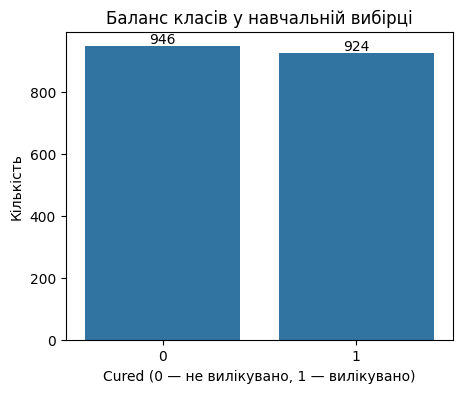

In [9]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=y_train)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Баланс класів у навчальній вибірці')
plt.xlabel('Cured (0 — не вилікувано, 1 — вилікувано)')
plt.ylabel('Кількість')
plt.show()

**Висновок:**  
Класи **збалансовані**: у навчальній вибірці 946 спостережень класу 0 (50.6 %) і 924 — класу 1 (49.4 %); у тестовій — 231 і 237. Баланс важливий для оцінки: при сильному дисбалансі модель могла б отримати високу Accuracy, просто завжди передбачаючи більший клас, і не розпізнавати менший. У нашому випадку Accuracy є інформативною метрикою, але для повноти її все одно варто доповнювати precision, recall і F1-score.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

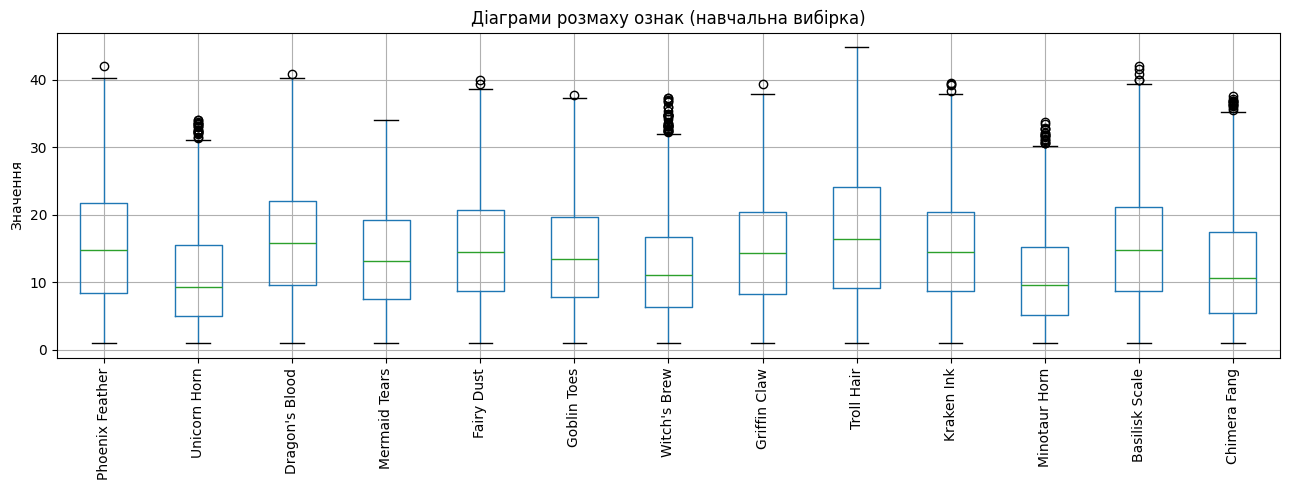

In [10]:
X_train.boxplot(figsize=(13, 5), rot=90)
plt.title('Діаграми розмаху ознак (навчальна вибірка)')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [11]:
# Правило 1.5 IQR (тільки на навчальній вибірці)
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers = ((X_train < lower) | (X_train > upper)).sum().sort_values(ascending=False)
outliers_table = pd.DataFrame({'Кількість викидів': outliers,
                               'Частка, %': (outliers / len(X_train) * 100).round(2)})
display(outliers_table)

rows_with_outliers = ((X_train < lower) | (X_train > upper)).any(axis=1).sum()
print(f'Рядків, що мають хоча б один викид: {rows_with_outliers} '
      f'з {len(X_train)} ({rows_with_outliers / len(X_train):.1%})')

,Кількість викидів,"Частка, %"
Witch's Brew,33,1.76
Unicorn Horn,20,1.07
Minotaur Horn,18,0.96
Chimera Fang,13,0.70
Basilisk Scale,5,0.27
Kraken Ink,4,0.21
Fairy Dust,2,0.11
Phoenix Feather,1,0.05
Dragon's Blood,1,0.05
Griffin Claw,1,0.05


Рядків, що мають хоча б один викид: 99 з 1870 (5.3%)


**Висновок про викиди:**  
За правилом 1.5 IQR найбільше потенційних викидів у ознаках **Witch's Brew (33, 1.76 %)**, **Unicorn Horn (20)**, **Minotaur Horn (18)** та **Chimera Fang (13)** — саме тих, що мають правосторонню асиметрію; у Mermaid Tears і Troll Hair викидів немає. Загалом хоча б один викид мають 99 рядків із 1870 (5.3 %). Видаляти їх без перевірки не варто: значення не виходять за межі правдоподібного діапазону (максимуми 34–42 при діапазоні інших ознак до 45), тобто це скоріше «хвіст» скошеного розподілу, а не помилки вимірювання. Крім того, Witch's Brew — друга за силою зв'язку з `Cured` ознака, і її крайні значення можуть нести корисну інформацію, а видалення 5 % рядків зменшило б навчальну вибірку.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

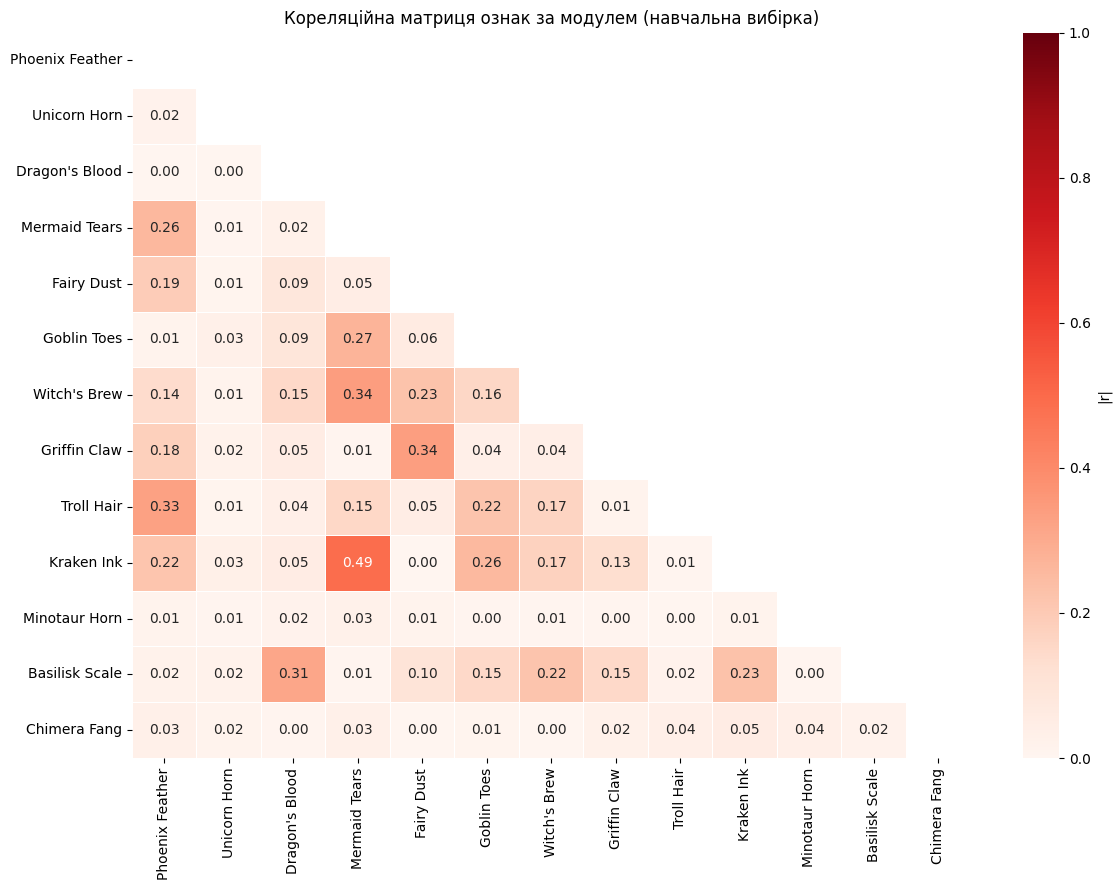

Найбільш корельовані пари ознак:
Kraken Ink      Mermaid Tears      0.491
Witch's Brew    Mermaid Tears      0.343
Griffin Claw    Fairy Dust         0.339
Troll Hair      Phoenix Feather    0.330
Basilisk Scale  Dragon's Blood     0.313
dtype: float64


In [12]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool))      # маскуємо верхній трикутник і діагональ

plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1,
            linewidths=0.5, cbar_kws={'label': '|r|'})
plt.title('Кореляційна матриця ознак за модулем (навчальна вибірка)')
plt.tight_layout()
plt.show()

top_pairs = mtx.where(~mask).stack().sort_values(ascending=False)
print('Найбільш корельовані пари ознак:')
print(top_pairs.head(5).round(3))

,Кореляція з Cured
Troll Hair,0.489
Witch's Brew,0.247
Goblin Toes,0.053
Chimera Fang,0.047
Basilisk Scale,-0.042
Kraken Ink,-0.027
Minotaur Horn,0.022
Phoenix Feather,0.021
Fairy Dust,0.014
Dragon's Blood,0.010


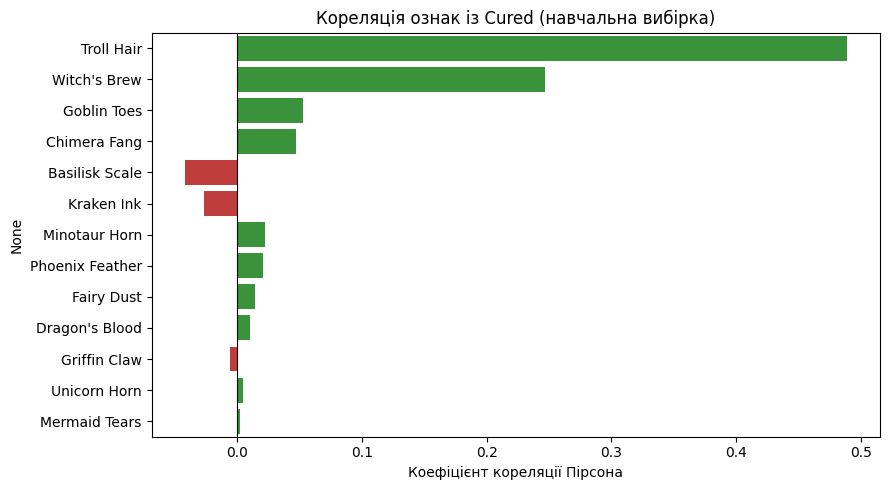

In [13]:
# Кореляція кожної ознаки з Cured (тільки навчальна вибірка)
target_corr = (pd.concat([X_train, y_train], axis=1).corr()['Cured']
               .drop('Cured').sort_values(key=abs, ascending=False))
display(target_corr.round(3).to_frame('Кореляція з Cured'))

plt.figure(figsize=(9, 5))
sns.barplot(x=target_corr.values, y=target_corr.index,
            palette=['tab:green' if v > 0 else 'tab:red' for v in target_corr.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Кореляція ознак із Cured (навчальна вибірка)')
plt.xlabel('Коефіцієнт кореляції Пірсона')
plt.tight_layout()
plt.show()

**Висновок про кореляції:**  
Найбільш корельовані пари ознак: **Kraken Ink — Mermaid Tears (0.491)**, Witch's Brew — Mermaid Tears (0.343), Griffin Claw — Fairy Dust (0.339), Troll Hair — Phoenix Feather (0.330), Basilisk Scale — Dragon's Blood (0.313). Ці зв'язки помірні, жодна пара не перевищує 0.5, тому сильної мультиколінеарності немає і всі ознаки можна залишити. З цільовою змінною найсильніше пов'язані **Troll Hair (r = 0.489)** та **Witch's Brew (r = 0.247)**; кореляція решти ознак із `Cured` за модулем не перевищує 0.06. Водночас слабка парна кореляція не означає, що ознака непотрібна: у логістичній регресії Mermaid Tears і Phoenix Feather отримали великі від'ємні коефіцієнти (−1.79 і −1.51), бо корелюють із сильними предикторами й уточнюють їхній вплив.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)     # параметри обчислюються лише на train
X_test_scaled = scaler.transform(X_test)           # test тільки трансформується

print('Середні після стандартизації (train):', np.round(X_train_scaled.mean(axis=0), 3)[:5], '...')
print('Стандартні відхилення (train):', np.round(X_train_scaled.std(axis=0), 3)[:5], '...')

Середні після стандартизації (train): [ 0.  0.  0. -0. -0.] ...
Стандартні відхилення (train): [1. 1. 1. 1. 1.] ...


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

base_accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy базової логістичної регресії: {base_accuracy:.4f}\n')
print(classification_report(y_test, y_pred, digits=3))

coef = pd.Series(model.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print('Коефіцієнти моделі (за модулем):')
print(coef.round(3))

Accuracy базової логістичної регресії: 0.8932

              precision    recall  f1-score   support

           0      0.888     0.896     0.892       231
           1      0.898     0.890     0.894       237

    accuracy                          0.893       468
   macro avg      0.893     0.893     0.893       468
weighted avg      0.893     0.893     0.893       468

Коефіцієнти моделі (за модулем):
Troll Hair         3.375
Witch's Brew       2.319
Mermaid Tears     -1.788
Phoenix Feather   -1.509
Goblin Toes       -0.879
Fairy Dust        -0.871
Basilisk Scale    -0.819
Kraken Ink        -0.457
Griffin Claw       0.305
Dragon's Blood     0.238
Chimera Fang       0.095
Unicorn Horn      -0.072
Minotaur Horn      0.042
dtype: float64


### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

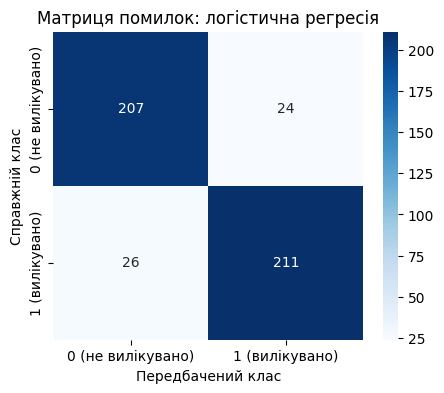

TN = 207, FP = 24, FN = 26, TP = 211
Хибнопозитивних (передбачено «вилікувано», а насправді ні): 24
Хибнонегативних (передбачено «не вилікувано», а насправді так): 26


In [16]:
conf = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['0 (не вилікувано)', '1 (вилікувано)'],
            yticklabels=['0 (не вилікувано)', '1 (вилікувано)'])
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок: логістична регресія')
plt.show()

tn, fp, fn, tp = conf.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')
print(f'Хибнопозитивних (передбачено «вилікувано», а насправді ні): {fp}')
print(f'Хибнонегативних (передбачено «не вилікувано», а насправді так): {fn}')

In [17]:
results = pd.DataFrame({'Справжній клас': y_test.values,
                        'Передбачений клас': y_pred}, index=y_test.index)
results['Збіг'] = np.where(results['Справжній клас'] == results['Передбачений клас'], '✓', '✗')
results.sample(10, random_state=42)

,Справжній клас,Передбачений клас,Збіг
1133,0,1,✗
1018,0,0,✓
1761,1,0,✗
564,1,1,✓
1467,1,1,✓
1927,0,0,✓
408,1,1,✓
2094,1,1,✓
532,0,0,✓
291,1,1,✓


**Висновок щодо якості логістичної регресії:**  
Базова логістична регресія досягла **Accuracy = 0.893** на тестовій вибірці (418 правильних прогнозів із 468). Метрики обох класів близькі: precision 0.888 / 0.898 і recall 0.896 / 0.890, F1 ≈ 0.89. За матрицею помилок **хибнонегативних (FN = 26)** лише трохи більше, ніж **хибнопозитивних (FP = 24)**, тобто модель не має перекосу в бік жодного класу. Однієї Accuracy недостатньо: вона не показує, яких саме помилок припускається модель. У цій задачі FP (модель вважає, що принцесу вилікувано, а насправді ні) небезпечніший за FN, тому варто окремо контролювати precision класу 1 та recall класу 0. Серед 10 випадкових тестових прикладів модель помилилася у двох (один FP і один FN).

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
from scipy.stats import loguniform

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 500, 1000],
}
param_dist = {
    'C': loguniform(1e-3, 1e3),            # неперервний розподіл значень C
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 300, 500, 1000],
}
print('Комбінацій у GridSearchCV:', 5 * 3 * 3)

Комбінацій у GridSearchCV: 45


In [19]:
grid = GridSearchCV(LogisticRegression(), param_grid, cv=3,
                    scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('GridSearchCV — найкращі параметри:', grid.best_params_)
print(f'GridSearchCV — найкраща accuracy на крос-валідації: {grid.best_score_:.4f}')

GridSearchCV — найкращі параметри: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
GridSearchCV — найкраща accuracy на крос-валідації: 0.8674


In [20]:
random_search = RandomizedSearchCV(LogisticRegression(), param_dist, n_iter=20, cv=3,
                                   scoring='accuracy', random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, y_train)

print('RandomizedSearchCV — найкращі параметри:', random_search.best_params_)
print(f'RandomizedSearchCV — найкраща accuracy на крос-валідації: {random_search.best_score_:.4f}')

RandomizedSearchCV — найкращі параметри: {'C': np.float64(24.658329458549105), 'max_iter': 100, 'solver': 'lbfgs'}
RandomizedSearchCV — найкраща accuracy на крос-валідації: 0.8674


In [21]:
# Обираємо пошук із кращою якістю на крос-валідації (тестову вибірку для вибору не використовуємо)
best_search = grid if grid.best_score_ >= random_search.best_score_ else random_search
best_name = 'GridSearchCV' if best_search is grid else 'RandomizedSearchCV'
best_lr = best_search.best_estimator_

y_pred_best = best_lr.predict(X_test_scaled)
tuned_accuracy = accuracy_score(y_test, y_pred_best)

print(f'Обрано модель з {best_name}: {best_search.best_params_}')
print(f'Accuracy на тесті: базова = {base_accuracy:.4f}, після підбору = {tuned_accuracy:.4f} '
      f'(різниця {tuned_accuracy - base_accuracy:+.4f})\n')
print(classification_report(y_test, y_pred_best, digits=3))

Обрано модель з GridSearchCV: {'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}
Accuracy на тесті: базова = 0.8932, після підбору = 0.8932 (різниця +0.0000)

              precision    recall  f1-score   support

           0      0.888     0.896     0.892       231
           1      0.898     0.890     0.894       237

    accuracy                          0.893       468
   macro avg      0.893     0.893     0.893       468
weighted avg      0.893     0.893     0.893       468



**Висновок про підбір параметрів:**  
**GridSearchCV** обрав `C = 10, solver = 'lbfgs', max_iter = 100`, а **RandomizedSearchCV** — `C ≈ 24.66, solver = 'lbfgs', max_iter = 100`; обидва методи дали однакову точність на крос-валідації — **0.8674**. Отже, обидва пошуки дійшли висновку, що варто послабити регуляризацію (C > 1), а вибір solver і max_iter на результат практично не впливає. Однак на тестовій вибірці якість **не змінилася**: Accuracy залишилася 0.8932, а метрики класів — ідентичні базовій моделі. Причина в тому, що для стандартизованих даних без мультиколінеарності значення `C = 1` за замовчуванням уже близьке до оптимального, а обмеженням моделі є сама лінійна межа рішень, яку зміна гіперпараметрів не усуває. RandomizedSearchCV досяг того самого результату за 20 комбінацій замість 45, тобто був ефективнішим.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

,Accuracy,F1-score
Модель,,
SVC,0.9594,0.9600
Логістична регресія (базова),0.8932,0.8941
Логістична регресія (після підбору),0.8932,0.8941
Дерево рішень,0.8654,0.8657


Найкраща модель за F1-score: SVC


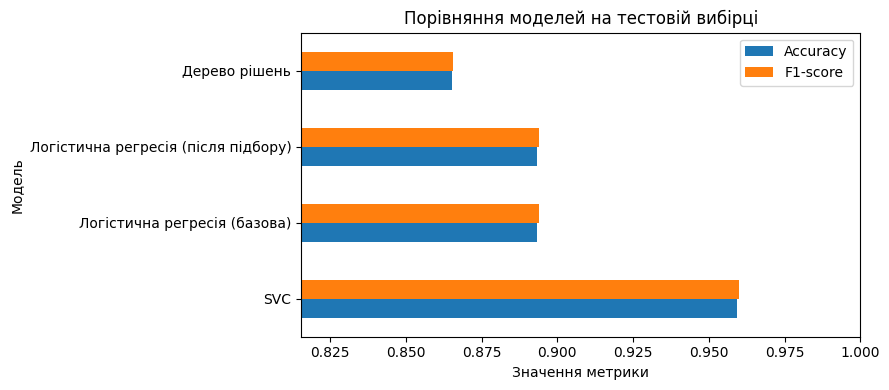

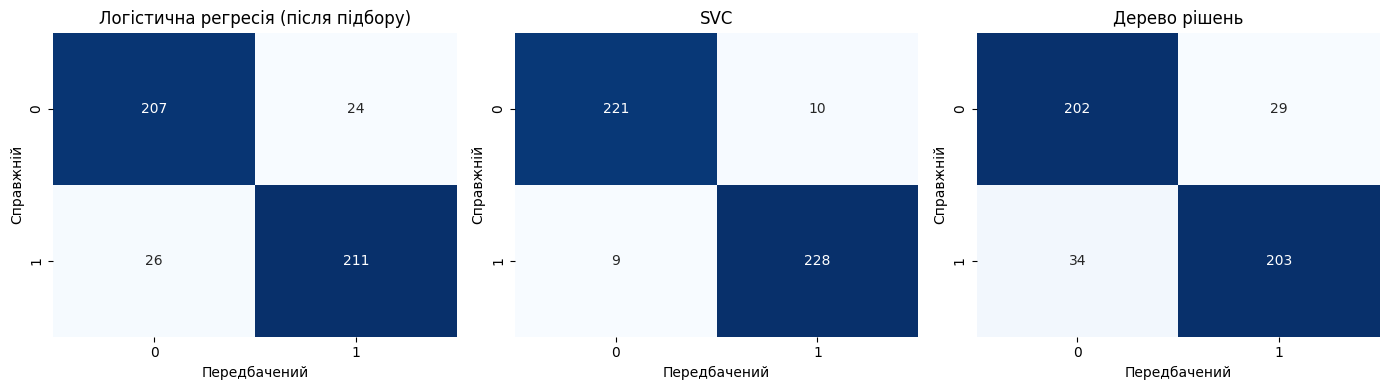

In [22]:
models = {
    'Логістична регресія (базова)': LogisticRegression(),
    'Логістична регресія (після підбору)': best_lr,
    'SVC': SVC(),
    'Дерево рішень': DecisionTreeClassifier(random_state=42),
}

rows = []
predictions = {}
for name, m in models.items():
    m.fit(X_train_scaled, y_train)                 # усі моделі — на тих самих даних
    pred = m.predict(X_test_scaled)
    predictions[name] = pred
    rows.append({'Модель': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'F1-score': f1_score(y_test, pred)})

comparison = pd.DataFrame(rows).set_index('Модель').sort_values('F1-score', ascending=False)
display(comparison.round(4))

best_model_name = comparison.index[0]
print(f'Найкраща модель за F1-score: {best_model_name}')

comparison.plot(kind='barh', figsize=(9, 4), xlim=(comparison.values.min() - 0.05, 1))
plt.title('Порівняння моделей на тестовій вибірці')
plt.xlabel('Значення метрики')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ['Логістична регресія (після підбору)', 'SVC', 'Дерево рішень']):
    sns.heatmap(confusion_matrix(y_test, predictions[name]), annot=True, fmt='d',
                cmap='Blues', cbar=False, ax=ax)
    ax.set(title=name, xlabel='Передбачений', ylabel='Справжній')
plt.tight_layout()
plt.show()

### 13. Висновки до лабораторної роботи

1. **Особливості даних.** Датасет *Cure the Princess* містить 2338 спостережень, 13 числових ознак і бінарну цільову змінну `Cured`. Пропусків і дублікатів немає, класи збалансовані (≈ 50 / 50), ознаки мають подібні діапазони, але різні середні, а частина з них — правосторонню асиметрію, тому перед лінійними моделями застосовано стандартизацію.

2. **Викиди та кореляції (навчальна вибірка).** Потенційні викиди за правилом 1.5 IQR є в 11 ознаках, найбільше — у Witch's Brew (33), Unicorn Horn (20) і Minotaur Horn (18); вони мають 5.3 % рядків, але є правдоподібними значеннями хвоста розподілу, тому їх не видаляли. Між ознаками лише помірні кореляції (максимум 0.491 для Kraken Ink — Mermaid Tears), мультиколінеарності немає. З `Cured` найсильніше пов'язані Troll Hair (0.489) і Witch's Brew (0.247).

3. **Базова логістична регресія** досягла Accuracy 0.893 і F1-score 0.894 на тестовій вибірці; помилки розподілені рівномірно між класами (FP = 24, FN = 26).

4. **Підбір гіперпараметрів** через GridSearchCV (`C = 10`) і RandomizedSearchCV (`C ≈ 24.7`) з `solver = 'lbfgs'` не покращив тестові метрики: Accuracy залишилася 0.893. Стандартні параметри вже були близькими до оптимальних, а якість логістичної регресії обмежує лінійність її межі рішень.

5. **Найкраща модель — SVC** (Accuracy 0.959, F1-score 0.960). Вона правильно класифікувала приблизно на 31 тестовий приклад більше, ніж логістична регресія (0.893 / 0.894), і значно випередила дерево рішень (0.865 / 0.866). Перевага SVC пояснюється ядром RBF, яке будує нелінійну межу між класами й враховує взаємодії ознак, недоступні лінійній логістичній регресії; стандартизація даних також сприяє його роботі. Одиночне дерево рішень без обмеження глибини схильне до перенавчання, тому показало найнижчу якість. Логістична регресія залишається корисною як інтерпретована базова модель: її коефіцієнти прямо показують, які інгредієнти підвищують (Troll Hair, Witch's Brew) чи знижують (Mermaid Tears, Phoenix Feather) шанси вилікувати принцесу.